In [1]:
import numpy as np
from tensorflow.keras.preprocessing import image

In [2]:
from tensorflow.keras.models import load_model

loaded_model = load_model(
    "../models/pneumovision_transfer_model.h5"
)

In [3]:
def predict_xray(img_path):

    img = image.load_img(
        img_path,
        target_size=(224,224)
    )

    img_array = image.img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.expand_dims(
        img_array,
        axis=0
    )

    prediction = loaded_model.predict(img_array)
    probability = prediction[0][0]

    if probability > 0.5:
        result = "PNEUMONIA"
    else:
        result = "NORMAL"

    print(f"Prediction: {result}")
    print(f"Confidence: {probability:.4f}")

Unseen X-ray Prediction Testing

In [4]:
import os

unseen_path = "../data/unseen_images"
os.listdir(unseen_path)

['normal_xray.webp',
 'normal_xray1.jpg',
 'normal_xray2.jpg',
 'pneumonia_1.jpeg',
 'pneumonia_2.jpeg',
 'pneumonia_3.jpeg']

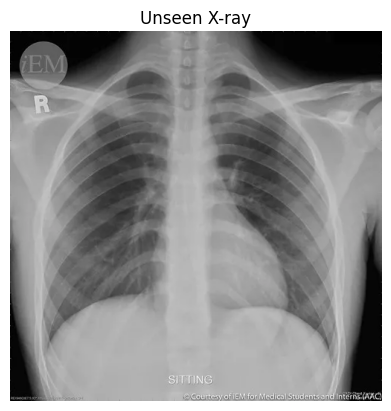

In [9]:
# First Image 
import matplotlib.pyplot as plt
from PIL import Image

sample_path = os.path.join(
    unseen_path,
    os.listdir(unseen_path)[0]
)

img = Image.open(sample_path)

plt.imshow(img, cmap="gray")
plt.title("Unseen X-ray")
plt.axis("off")
plt.show()

In [5]:
# Testing All
for img_name in os.listdir(unseen_path):

    img_path = os.path.join(
        unseen_path,
        img_name
    )

    print(f"\nTesting: {img_name}")
    predict_xray(img_path)


Testing: normal_xray.webp
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 646ms/step
Prediction: NORMAL
Confidence: 0.2620

Testing: normal_xray1.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Prediction: NORMAL
Confidence: 0.4786

Testing: normal_xray2.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Prediction: NORMAL
Confidence: 0.0985

Testing: pneumonia_1.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
Prediction: NORMAL
Confidence: 0.1394

Testing: pneumonia_2.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Prediction: PNEUMONIA
Confidence: 0.6104

Testing: pneumonia_3.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
Prediction: PNEUMONIA
Confidence: 0.9516
